# Social dimensions of Eaton and Palisades fires
## Week 8 - Discussion section

In January 2025, the Eaton and Palisades fires burned thousands of homes in Los Angeles County. A wildfire’s impact depends not only on where it burns but also on who lives there: communities differ in their resources to evacuate, recover and rebuild. Here we will combine fire perimeters with the Environmental Justice Index to look at the social dimensions of these two fires. In this discussion section, you will:

- explore the EJI metadata and choose variables that could influence a community’s response to a wildfire
spatially join census tracts with the fire perimeters

- clip census tracts to the fire perimeters and compare clipping with a spatial join
make maps of the fire perimeters over a basemap


- compare an EJI variable across the two fire areas and discuss what the differences could mean for wildfire relief

## Setup

Find fire perimeters for the Eaton and Palisades fires that occurred in Los Angeles County in 2025. There are several datasets with this information online. You will need to independently select one from a reputable source (it may be more than one file). These are the same files you will use for assignment 4.

Add the fire perimeter datasets to the data directory in your eds220-discussion-sections directory.

Download the 2024 Environmental Justice Index data for California in the geodatabase data format. Add it to the data directory in your eds220-discussion-sections directory.

## About the data

The [Environmental Justice Index (EJI)](https://www.atsdr.cdc.gov/place-health/php/eji/index.html) is a national, place-based tool that measures the cumulative impacts of environmental burden on human health and health equity. It is produced by the Centers for Disease Control and Prevention (CDC) and the Agency for Toxic Substances and Disease Registry (ATSDR) [@CDC_ATSDR_EJI].

The EJI ranks every census tract in the United States on 36 environmental, social and health factors, grouped into three modules:

- **Social vulnerability**: racial/ethnic minority status, socioeconomic status, household characteristics and housing type.
- **Environmental burden**: air pollution, potentially hazardous and toxic sites, built environment, transportation infrastructure and water pollution.
- **Health vulnerability**: pre-existing chronic disease burden.

The 2024 release also includes a separate climate burden module with indicators for extreme heat, wildfire and other extreme events. You can interactively explore this dataset through the [EJI explorer](https://www.atsdr.cdc.gov/place-health/php/eji/eji-explorer.html).

The EJI download includes a data dictionary describing every variable. The first letters of each column name tell you what kind of value it holds:

- `E_`: estimates. For example, `E_NOINT` is the percentage of persons without internet in the census tract.
- `EPL_`: percentile ranks of those estimates, from 0 to 1. For example, `EPL_NOINT` is the tract's percentile rank for `E_NOINT`.
- `SPL_`: summed ranks for domains, modules or the overall score. For example, `SPL_EJI` is the sum of the percentile ranks of the environmental burden, health vulnerability and social vulnerability modules (`RPL_EBM`, `RPL_HVM` and `RPL_SVM`).
- `RPL_`: percentile ranks for domains, modules or the overall score, from 0 to 1.

Values of -999 represent "no data". The census tract boundaries come from the 2020 TIGER/Line Files.

The **fire perimeters** are polygons outlining the area burned by each fire. Different agencies publish perimeters for the Eaton and Palisades fires, and they may differ in how and when they were mapped. Read the metadata of the dataset you select so you know where its perimeters come from and how current they are.

## 1. Metadata exploration

a. Open the data dictionary that came with your EJI download. Update the path to match your `data` directory:

```python
eji_dictionary = pd.read_csv('data/EJI_2024_California/EJI_DATADICTIONARY_2024.csv',
                             skiprows=1,
                             encoding='cp1252')
```

The `skiprows=1` parameter skips the first row of the file, which is a note about the dataset rather than the column names. The `encoding='cp1252'` parameter tells `pandas` that the file uses Windows text encoding. Without it, `pandas` assumes UTF-8 encoding and raises a `UnicodeDecodeError` when it reaches characters like curly apostrophes.

b. Take a first look at `eji_dictionary` on its own. What are its columns? What does each row describe?

c. In the `MODULE` column, `SVM` stands for the social vulnerability module. Run the code below. Then:

    1. Have one person explain to the group what the code is doing.
    2. Add comments explaining what each line does.

```python
eji_dictionary['2024 VARIABLE NAME'] = eji_dictionary['2024 VARIABLE NAME'].str.strip()

pd.set_option('display.max_colwidth', 120)
eji_dictionary.loc[eji_dictionary['MODULE'] == 'SVM', ['2024 VARIABLE NAME', '2024 VARIABLE DESCRIPTION', 'DOMAIN']]
```

d. With your team, **select a few variables** that, in your opinion, could influence a community's response to a wildfire. You'll be working with some of them in the following exercises. The [EJI technical documentation](https://www.atsdr.cdc.gov/place-health/media/pdfs/2024/10/EJI_2024_Technical_Documentation.pdf) describes each indicator: pages 40–41 list all the indicators, and pages 43–60 have a page for each indicator in the social vulnerability module, with its definition, data source and why it matters.


In [49]:
# Import libraries
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import contextily as ctx


In [6]:
# Open data dictionary

eji_dictionary = pd.read_csv('data/EJI_2024_California/EJI_DATADICTIONARY_2024.csv',
                             skiprows=1,
                             encoding='cp1252')
eji_dictionary

,2024 VARIABLE NAME,2022 VARIABLE NAME,2024 VARIABLE DESCRIPTION,MODULE,DOMAIN,DATA SOURCE,2024 TABLE FIELD CALCULATION,NOTES
0,STATEFP,STATEFP,State Federal Information Processing Series (F...,No Value,No Value,No Value,No Value,No Value
1,COUNTYFP,COUNTYFP,County FIPS code,No Value,No Value,No Value,No Value,No Value
2,TRACTCE,TRACTCE,Census tract geographic code,No Value,No Value,The U.S. Census Bureau 2020 Cartographic Bound...,No Value,No Value
3,AFFGEOID,AFFGEOID,Census tract identifier; a concatenation of cu...,No Value,No Value,No Value,No Value,No Value
4,GEOID,GEOID,"11-digit census tract identifier, which is a c...",No Value,No Value,No Value,2020 State FIPS + 2020 County FIPS + 2020 Cens...,Connecticut tracts are using updated 2022 Coun...
...,...,...,...,...,...,...,...,...
165,TWOMORE,No Value,"Adjunct variable - Two or More Races, Not Hisp...",No Value,No Value,2015-2019 Census Bureau American Community Sur...,DP05_0085E,No Value
166,E_TWOMORE,No Value,Adjunct variable - Percentage of Two or More R...,No Value,No Value,2015-2019 Census Bureau American Community Sur...,DP05_0085PE,No Value
167,Tribe_PCT_Tract,No Value,Percent of census tract that intersects with T...,No Value,No Value,The U.S. Census Bureau 2023 American Indian Ar...,No Value,Sum of the geographical intersections of Triba...
168,Tribe_Names,No Value,Concatenation of Tribal land names that inters...,No Value,No Value,The U.S. Census Bureau 2023 American Indian Ar...,No Value,No Value


In [7]:
eji_dictionary['2024 VARIABLE NAME'] = eji_dictionary['2024 VARIABLE NAME'].str.strip() # Cleaning 2024 Variable Names 

pd.set_option('display.max_colwidth', 120) # Constraining maximum width of columns (2024 Variable Description does not force other columns out of view)
eji_dictionary.loc[eji_dictionary['MODULE'] == 'SVM', ['2024 VARIABLE NAME', '2024 VARIABLE DESCRIPTION', 'DOMAIN']] # Only display variables from social vulnerability module (and only the three columns listed)

,2024 VARIABLE NAME,2024 VARIABLE DESCRIPTION,DOMAIN
19,E_MINRTY,"Percentage of persons who identify as Hispanic or Latino (of any race); Black and African American, Not Hispanic or ...",SVM DOM1
20,EPL_MINRTY,Percentile rank of percentage of persons who identify as Hispanic or Latino (of any race); Black and African America...,SVM DOM1
21,SPL_SVM_DOM1,Domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); Black and African A...,SVM DOM1
22,RPL_SVM_DOM1,Percentile rank of domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); ...,SVM DOM1
23,E_POV200,Percentage of persons with income below 200% of the federal poverty level,SVM DOM2
24,EPL_POV200,Percentile rank of the percentage of persons with income below 200% of federal poverty level,SVM DOM2
25,E_NOHSDP,Percentage of persons with no high school diploma (age 25+),SVM DOM2
26,EPL_NOHSDP,Percentile rank of percentage of persons with no high school diploma (age 25+),SVM DOM2
27,E_UNEMP,Percentage of persons who are unemployed,SVM DOM2
28,EPL_UNEMP,Percentile rank of the percentage of persons who are unemployed,SVM DOM2


## 2. Polygon intersection

a. Open the fire perimeters and the EJI data and do initial data exploration. 
b. Spatially join the EJI data with the Palisades fire perimeter using [`geopandas.sjoin()`](https://geopandas.org/en/stable/docs/reference/api/geopandas.sjoin.html) to get a `geopandas.GeoDataFrame` that will only have the census tracts intersecting the Palisades fire perimeter. 
c. Create an exploratory map showing 

    (1) the census tracts that intersect the Palisades fire perimeter and 
    (2) the Palisades fire perimeter. 

:::{.callout-tip appearance="minimal"}
Discuss how big the Palisades fire perimeter is in relation to the census tracts.
:::

d. Create the corresponding `geopandas.GeoDataFrame` and exploratory map for the Eaton fire. 

:::{.callout-tip appearance="minimal"}
Discuss how big the Eaton fire perimeter is in relation to the census tracts intersecting the Eaton fire perimeter.
:::

In [22]:
eji = gpd.read_file('data/EJI_2024_California/EJI_2024_California.gdb')

EJI CRS is:  PROJCS["USA_Contiguous_Albers_Equal_Area_Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102003"]] 

Palisades CRS is:  EPSG:4269


<Axes: >

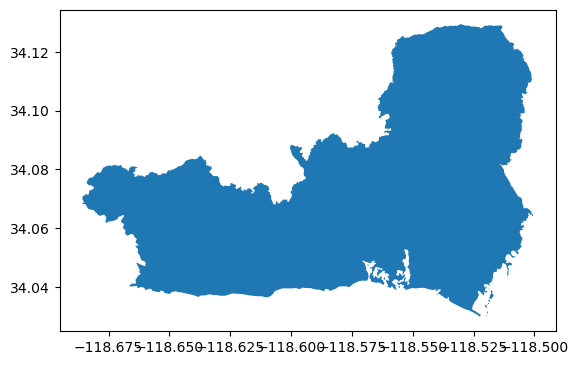

In [25]:
palisades = gpd.read_file('data/Palisades_Perimeter_20250121/Palisades_Perimieter_20250121.shp')

print("EJI CRS is: ", eji.crs, "\n")
print("Palisades CRS is: ", palisades.crs)
palisades.plot()

In [27]:
eji = eji.to_crs(palisades.crs)
assert eji.crs == palisades.crs

Census tracts intersecting palisades:  15


<Axes: >

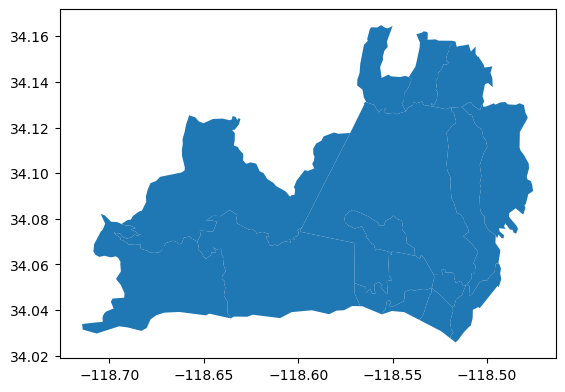

In [30]:
palisades_eji_join = gpd.sjoin(eji, palisades, how = "inner", predicate = "intersects")

print("Census tracts intersecting palisades: ", len(palisades_eji_join))
palisades_eji_join.plot()

/tmp/ipykernel_633781/411055297.py:10: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


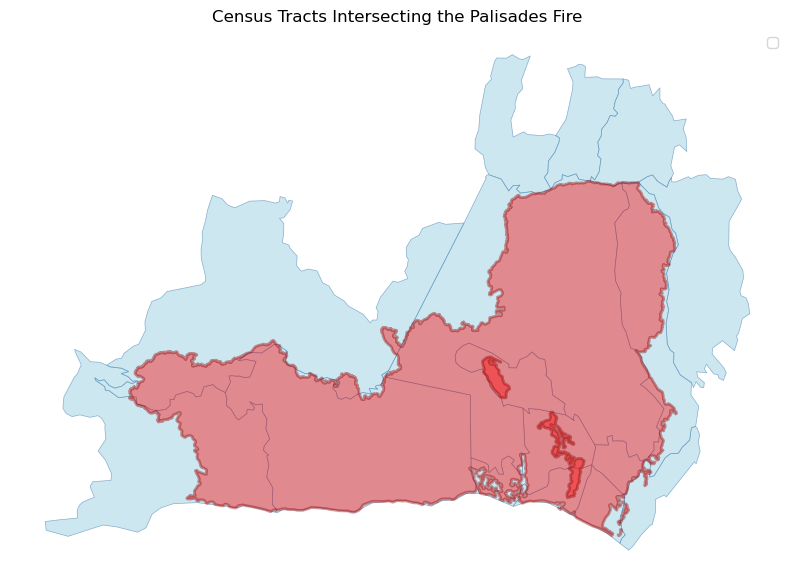

In [41]:
fig, ax = plt.subplots(1, 1, figsize=(10,10))

palisades_eji_join.plot(ax=ax, alpha = 0.6, color = "lightblue", edgecolor = 'steelblue',
                       linewidth = 0.5, label = "Census tracts")

palisades.plot(ax=ax, alpha = 0.4, color = "red", edgecolor = "darkred",
              linewidth=2, label = "Palisades perimeter")

ax.set_title("Census Tracts Intersecting the Palisades Fire")
ax.legend()
ax.axis('off')
plt.tight_layout

plt.show()

In [37]:
eaton = gpd.read_file('data/Eaton_Perimeter_20250121/Eaton_Perimeter_20250121.shp')

In [38]:
assert eji.crs == eaton.crs

In [42]:
eaton_eji_join = gpd.sjoin(eji, eaton, how = "inner", predicate = "intersects")

/tmp/ipykernel_633781/2654409338.py:10: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


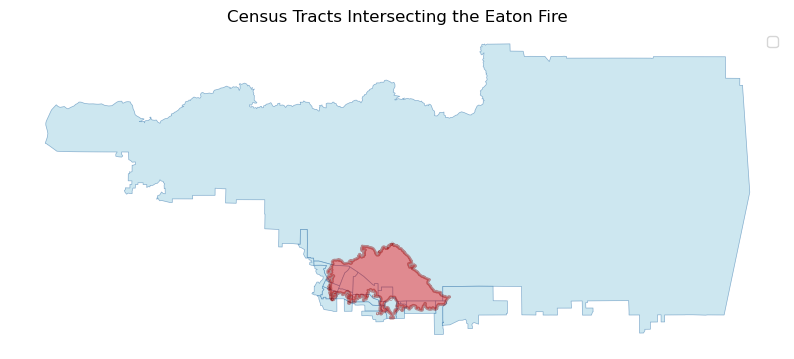

In [43]:
fig, ax = plt.subplots(1, 1, figsize=(10,10))

eaton_eji_join.plot(ax=ax, alpha = 0.6, color = "lightblue", edgecolor = 'steelblue',
                       linewidth = 0.5, label = "Census tracts")

eaton.plot(ax=ax, alpha = 0.4, color = "red", edgecolor = "darkred",
              linewidth=2, label = "Eaton perimeter")

ax.set_title("Census Tracts Intersecting the Eaton Fire")
ax.legend()
ax.axis('off')
plt.tight_layout

plt.show()

## 3. Polygon clipping

a. Clip the census tracts to the Palisades fire perimeter using [`geopandas.clip()`](https://geopandas.org/en/stable/docs/reference/api/geopandas.clip.html). 
b. Do the same for the Eaton fire perimeter. 
c. Visualize your data. 

:::{.callout-tip appearance="minimal"}
Discuss with your group the difference between a spatial join (step 2) and clipping (step 3). 
When transforming geospatial data, make sure you understand the difference and what your goal is!

When a census tract is clipped to the fire perimeter, only part of the tract is left. Do the EJI values of a clipped tract describe the people living inside the fire perimeter, or the whole tract? How does this affect what you can conclude from each method?
:::

<Axes: >

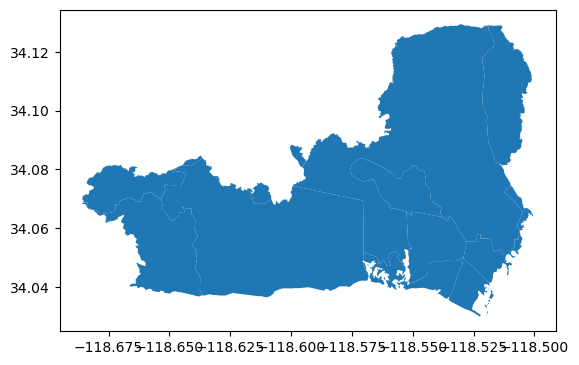

In [47]:
# Clip Palisades
palisades_clip = gpd.clip(eji, palisades)
palisades_clip.plot()

<Axes: >

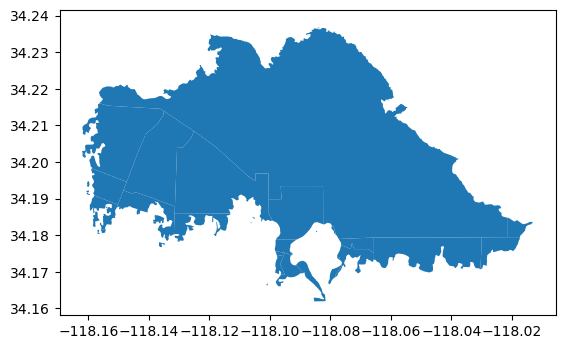

In [48]:
# Clip Eaton
eaton_clip = gpd.clip(eji, eaton)
eaton_clip.plot()

## 4. Visualize fire perimeters with a basemap

To add a basemap to our plot we will be using the [`contextily`](https://contextily.readthedocs.io/en/latest/) library. 

a. Import the `contextily` library at the top of your notebook as `ctx`. This library is already installed in the EDS 220 environment.

b. Use and update the code below to plot the fire perimeters adding a basemap: 

```python
fig, ax = plt.subplots(1, 1, figsize=(14, 12))

# ADD FIRE PERIMETERS: UPDATE FILL TRANSPARENCY AND COLOR

# ADD LEGEND OR ANNOTATION TO IDENTIFY EACH FIRE

# Add basemap using contextily
# Call it after plotting the perimeters so it covers their extent,
# and pass the CRS of your perimeters so the tiles line up with them
ctx.add_basemap(ax, crs=UPDATE.crs, source=ctx.providers.Esri.WorldStreetMap)

# ADD TITLE

ax.axis('off')

plt.tight_layout()
plt.show()
```

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14, 12))

# ADD FIRE PERIMETERS: UPDATE FILL TRANSPARENCY AND COLOR

# ADD LEGEND OR ANNOTATION TO IDENTIFY EACH FIRE

# Add basemap using contextily
# Call it after plotting the perimeters so it covers their extent,
# and pass the CRS of your perimeters so the tiles line up with them
ctx.add_basemap(ax, crs=UPDATE.crs, source=ctx.providers.Esri.WorldStreetMap)

# ADD TITLE

ax.axis('off')

plt.tight_layout()
plt.show()

## 5. Visualize EJI data

a. Decide whether you will use the census tracts from the spatial join (step 2) or from the clipping (step 3) for this map. Assign them to `palisades_tracts` and `eaton_tracts`, and write one sentence justifying your choice.

b. Use and update the code below to plot one of the variables you and your team explored in step 1 as being relevant to a community's response to a wildfire.

```{python}
#| code-fold: true
#| eval: false

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

# UPDATE WITH YOUR EJI VARIABLE FROM STEP 1
eji_variable = ''

# Find common min/max for legend range
vmin = min(palisades_tracts[eji_variable].min(), eaton_tracts[eji_variable].min())
vmax = max(palisades_tracts[eji_variable].max(), eaton_tracts[eji_variable].max())

# Plot Palisades census tracts
palisades_tracts.plot(
    column=eji_variable,
    vmin=vmin, vmax=vmax,
    legend=False,
    ax=ax1,
)
ax1.set_title('UPDATE TITLE')
ax1.axis('off')

# Plot Eaton census tracts
eaton_tracts.plot(
    column=eji_variable,
    vmin=vmin, vmax=vmax,
    legend=False,
    ax=ax2,
)
ax2.set_title('UPDATE TITLE')
ax2.axis('off')

# Add overall title
fig.suptitle('YOUR VARIABLE HERE - Fire Areas Comparison')

# Add shared colorbar at the bottom
sm = plt.cm.ScalarMappable(norm=plt.Normalize(vmin=vmin, vmax=vmax))
cbar_ax = fig.add_axes([0.25, 0.08, 0.5, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_label('YOUR VARIABLE HERE (WITH UNITS)')

plt.show()
```

:::{.callout-tip appearance="minimal"}
With your team, write a paragraph discussing how or whether this variable is distributed differently across the two fire perimeters. What kind of implications could this have in terms of wildfire relief?

Then, list at least two things this data *cannot* tell you about the people affected by the fires. Think about the area each value describes, when the data was collected and what your variable measures.
:::